# 01 — Multimodel precipitation-type verification against mPING (CSI, bias, POD, FAR)

This notebook verifies precipitation type (ptype) forecasts from five AI-NWP models (Aurora, GraphCast, Pangu-Weather, WXFormer, FuXi) and GFS against quality-controlled mPING reports for the 2021–22 cold season (1 Dec 2021 – 31 Mar 2022).

**Forecast systems (12 total).** Each AI model is scored twice: with the evidential deep neural network (**EDNN**) ptype and with the **Bourgouin** thermodynamic ptype. GFS is scored with its **native** ptype and with EDNN.

**Pipeline**

1. Filter mPING reports (synoptic hours, CONUS) and assign the observed class with `OBS_RULE`: the most-reported ptype with ties broken FZRA > IP > Snow > Rain (training-data rule, `"modal"`, default), or the most-reported ptype with ≥70 % agreement (`"consensus"`).
2. Pair each report with the 00Z initialization for each forecast day 1–7.
3. Collocate every report with the nearest model grid point (results cached to parquet).
4. Build one long table of predictions for all 12 systems.
5. Keep the **common-valid sample**: observation/day pairs where *all* systems have a valid prediction.
6. Compute one-vs-rest POD, FAR, CSI and frequency bias per system, forecast day and class.
7. Plot the CSI + frequency-bias heatmaps and the FAR + POD heatmaps.

**Outputs** (in `OUT` and `FIG`)

Outputs go to `verification_multimodel_modal/` and `figures_modal/` for the modal rule, and to `verification_multimodel/` and `figures/` for the consensus rule.

| File | Contents |
|---|---|
| `*_mping_collocations.parquet` | Cached collocations, one file per model |
| `collocation_qc.csv` | Grid-distance and invalid-code QC |
| `ednn_invalid_diagnostic.csv` | Summary of dropped EDNN rows |
| `common_valid_multimodel_predictions.parquet` | Common-valid sample; **input to notebook 02** |
| `multimodel_skill_by_day.csv` | All metrics per system / day / class |
| `multimodel_csi_bias_heatmap.pdf` | Figure: CSI and frequency bias |
| `multimodel_far_pod_heatmap.pdf` | Figure: FAR and POD |

> Run with **Kernel → Restart & Run All**; later cells depend on objects built in earlier ones.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize, ListedColormap
import re
from IPython.display import display

## 2. Configuration

Paths, verification period, spatial domain and class definitions.

- `OBS_RULE`: how the observed class is assigned. `"modal"` = most-reported ptype, ties broken FZRA > IP > Snow > Rain (the training-data rule), no agreement threshold. `"consensus"` = most-reported ptype, kept only if ≥ `CONSENSUS` % of reporters agree (ties impossible). Each rule has its own output and figure folders.
- `MAX_DIST_KM`: maximum report-to-grid-point distance for a valid match.
- Class codes follow the model output convention: 0 = Rain, 1 = Snow, 2 = Ice Pellet, 3 = Freezing Rain. Native GFS also uses −1 = no ptype diagnosed.

In [2]:
pd.set_option("display.max_columns", 100)

# ============================================================
# OBSERVED-CLASS RULE (must be identical in notebooks 01–04)
#   "modal":     most-reported ptype; ties broken FZRA > IP > Snow > Rain
#                (same rule as the EDNN training labels); no agreement threshold
#   "consensus": most-reported ptype, kept only with >= CONSENSUS % agreement
# Each rule writes to its own output and figure folders, so cached
# collocations (keyed by obs_id) from the two rules never mix.
# ============================================================
OBS_RULE = "modal"                    # "modal" | "consensus"
CONSENSUS = 70.0                      # used only when OBS_RULE == "consensus"
TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"

# ============================================================
# PATHS
# ============================================================

MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"

AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "WXFormer": AI_BASE / "wx_ptype",
    "FuXi": AI_BASE / "fuxi_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}
F = Path("/glade/work/sakor/AI_NWP")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ============================================================
# EXPERIMENT
# ============================================================

START = pd.Timestamp("2021-12-01 00:00:00")
END = pd.Timestamp("2022-04-01 00:00:00")  # exclusive
LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
MAX_DIST_KM = 30.0

PTYPE_COLS = {
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}

CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_CODES = {v: k for k, v in CLASS_NAMES.items()}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
FRZR_IP_CLASSES = ["Ice Pellet", "Freezing Rain"]

EPI_VARS = {
    "Rain": "ML_rain_epi", "Snow": "ML_snow_epi",
    "Ice Pellet": "ML_icep_epi", "Freezing Rain": "ML_frzr_epi",
}
ALE_VARS = {
    "Rain": "ML_rain_ale", "Snow": "ML_snow_ale",
    "Ice Pellet": "ML_icep_ale", "Freezing Rain": "ML_frzr_ale",
}

EXTRACT_VARS = [
    "ML_ptype",
    "ML_rain_ale", "ML_snow_ale", "ML_icep_ale", "ML_frzr_ale",
    "ML_rain_epi", "ML_snow_epi", "ML_icep_epi", "ML_frzr_epi",
    "BOURG_ptype", "GFS_ptype",
]

## 3. mPING quality control and forecast-day expansion

`prepare_mping` keeps reports that are
- inside the verification period,
- at 00/06/12/18 UTC (the AI-NWP output times),
- inside the CONUS box, and
- (consensus rule only) at or above the consensus threshold.

The observed class is the ptype with the highest reporter percentage. Ties (e.g. 50 % snow / 50 % ice pellets) are broken with the training-data hierarchy FZRA > IP > Snow > Rain; `obs_tie_resolved` flags these records. Under the consensus rule ties cannot occur, because the threshold is above 50 %.

`expand_forecast_days` makes 7 copies of each report, one per forecast day. Every copy is tied to a **00Z initialization**:
- A 00Z valid time belongs to the *previous* day's 00Z init (lead 24 h), so there are no 0-h leads.
- Forecast day *n* covers leads 24(n−1)+6 … 24n h.

In [3]:
def assign_obs_class(d):
    """Observed class from the mPING class percentages, following OBS_RULE.

    The class is the most-reported ptype. idxmax returns the FIRST column at the
    maximum, so ordering the columns by TIE_PRIORITY breaks ties as
    FZRA > IP > Snow > Rain. Percentages are rounded only for tie detection;
    the consensus threshold uses the unrounded values.
    """
    raw = d[TIE_PRIORITY].astype(float).fillna(0.0)
    if raw.to_numpy().max() <= 1.0:              # stored as fractions
        raw = raw * 100.0
    pct = raw.round(6)
    d = d.copy()
    d["obs_consensus"] = raw.max(axis=1)
    d["obs_tie_resolved"] = pct.eq(pct.max(axis=1), axis=0).sum(axis=1) > 1
    d["obs_class"] = pct.idxmax(axis=1).map(PTYPE_COLS)
    if OBS_RULE == "consensus":
        keep = d.obs_consensus >= CONSENSUS
    elif OBS_RULE == "modal":
        keep = d.obs_consensus > 0               # any reported ptype
    else:
        raise ValueError(f"unknown OBS_RULE {OBS_RULE!r}")
    return d[keep]

def prepare_mping(path):
    cols = ["datetime","lat","lon","report_count","sn_percent","ra_percent","pl_percent","fzra_percent"]
    d = pd.read_parquet(path, columns=cols)
    d["datetime"] = pd.to_datetime(d["datetime"])

    d = d[(d.datetime >= START) & (d.datetime < END)].copy()
    d = d[d.datetime.dt.hour.isin([0,6,12,18])].copy()
    d = d[d.lat.between(LAT_MIN,LAT_MAX) & d.lon.between(LON_MIN,LON_MAX)].copy()

    d = assign_obs_class(d).reset_index(drop=True)
    d["obs_id"] = np.arange(len(d), dtype=np.int64)
    return d[["obs_id","datetime","lat","lon","report_count",
              "obs_class","obs_consensus","obs_tie_resolved"]]

def expand_forecast_days(obs):
    out = []
    for day in range(1,8):
        x = obs.copy()
        h = x.datetime.dt.hour
        x["forecast_day"] = day
        x["lead_hour"] = np.where(h == 0, 24*day, h + 24*(day-1)).astype(np.int16)
        x["init_time"] = x.datetime - pd.to_timedelta(x.lead_hour, unit="h")
        out.append(x)
    return pd.concat(out, ignore_index=True)

obs = prepare_mping(MPING_PATH)
master = expand_forecast_days(obs)

assert master.groupby("obs_id").size().eq(7).all()
assert not (master.lead_hour == 0).any()

rule_txt = "modal, ties FZRA > IP > Snow > Rain" if OBS_RULE == "modal" else f">= {CONSENSUS:g}% consensus"
print(f"Observed-class rule: {rule_txt}")
print(f"mPING observations: {len(obs):,} (ties resolved by hierarchy: {obs.obs_tie_resolved.sum():,})")
print(f"Expanded verification rows: {len(master):,}")
print("\nLead hours by forecast day:")
print(master.groupby("forecast_day").lead_hour.apply(lambda x: sorted(x.unique())))
print("\nObserved classes:")
print(obs.obs_class.value_counts().reindex(CLASS_ORDER))

Observed-class rule: modal, ties FZRA > IP > Snow > Rain
mPING observations: 30,856 (ties resolved by hierarchy: 840)
Expanded verification rows: 215,992

Lead hours by forecast day:
forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object

Observed classes:
obs_class
Rain             11932
Snow             16116
Ice Pellet        1772
Freezing Rain     1036
Name: count, dtype: int64


## 4. Forecast file lookup and coverage check

`resolve_file` finds the NetCDF file for a model, init time and lead. If the expected file name isn't there, it falls back to a unique `*_{lead}.nc` match.

The coverage table below should show every required file present for every model before the (slow) collocation step runs.

In [4]:
FILE_PREFIX = {
    "Aurora": "aurora",
    "GraphCast": "graphcast",
    "Pangu-Weather": "pangu",
    "WXFormer": "wxformer",
    "FuXi":"fuxi",
    "GFS": "gfs",
}

def init_string(t):
    return pd.Timestamp(t).strftime("%Y-%m-%dT00Z")

def resolve_file(model, init_time, lead_hour):
    s = init_string(init_time)
    folder = MODEL_DIRS[model] / s
    lead = f"{int(lead_hour):03d}"

    expected = folder / f"{FILE_PREFIX[model]}_{s}_{lead}.nc"
    if expected.exists():
        return expected

    hits = sorted(folder.glob(f"*_{lead}.nc"))
    if len(hits) == 1:
        return hits[0]
    if len(hits) == 0:
        return None

    raise RuntimeError(f"Ambiguous files for {model}, {s}, +{lead} h: {hits}")

# Quick file-coverage check before expensive collocation
required = master[["init_time","lead_hour"]].drop_duplicates().sort_values(["init_time","lead_hour"])
coverage = []

for model in MODEL_DIRS:
    for r in required.itertuples(index=False):
        p = resolve_file(model, r.init_time, r.lead_hour)
        coverage.append({
            "model": model, "init_time": r.init_time, "lead_hour": r.lead_hour,
            "exists": p is not None, "path": str(p) if p else None
        })

coverage = pd.DataFrame(coverage)
display(coverage.groupby("model").exists.agg(["sum","count"]))
print("\nMissing files by model:")
display(coverage[~coverage.exists].groupby("model").size())

,sum,count
model,,
Aurora,3325,3325
FuXi,3325,3325
GFS,3325,3325
GraphCast,3325,3325
Pangu-Weather,3325,3325
WXFormer,3325,3325



Missing files by model:


Series([], dtype: int64)

## 5. Nearest-grid-point collocation

For each (init time, lead) file, every mPING report valid at that time is matched to the nearest grid point. The ptype and EDNN uncertainty variables are extracted there. The great-circle distance to the grid point is stored and checked against `MAX_DIST_KM`.

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1,lon1,lat2,lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def extract_points(ds, group, model):
    q = ds.sel(
        latitude=xr.DataArray(group.lat.to_numpy(), dims="obs"),
        longitude=xr.DataArray(group.lon.to_numpy(), dims="obs"),
        method="nearest"
    )

    r = group.reset_index(drop=True).copy()
    r["model"] = model
    r["grid_lat"] = np.asarray(q.latitude).squeeze()
    r["grid_lon"] = np.asarray(q.longitude).squeeze()
    r["grid_distance_km"] = haversine(
        r.lat.to_numpy(), r.lon.to_numpy(),
        r.grid_lat.to_numpy(), r.grid_lon.to_numpy()
    )
    r["spatial_match_valid"] = r.grid_distance_km <= MAX_DIST_KM

    for var in EXTRACT_VARS:
        if var in q:
            r[var] = np.asarray(q[var]).squeeze()

    return r

def collocate_model(model, master):
    out = []
    groups = master.groupby(["init_time","lead_hour"], sort=True)
    n = len(groups)

    for i, ((init_time, lead_hour), g) in enumerate(groups, 1):
        path = resolve_file(model, init_time, lead_hour)
        if path is None:
            print(f"[MISSING] {model}: {init_string(init_time)} +{lead_hour:03d}")
            continue

        if i == 1 or i % 100 == 0 or i == n:
            print(f"{model}: {i}/{n} | {init_string(init_time)} +{lead_hour:03d} | N={len(g)}")

        with xr.open_dataset(path, decode_timedelta=False) as ds:
            out.append(extract_points(ds, g, model))

    if not out:
        raise RuntimeError(f"No files collocated for {model}")

    d = pd.concat(out, ignore_index=True)
    d.to_parquet(OUT / f"{model.lower().replace('-','_')}_mping_collocations.parquet", index=False)
    return d

### 5.1 Run or load collocations

Collocations are cached. If a model's parquet file already exists it is loaded; otherwise it is generated. 

In [6]:
collocated = {}

for model in ["Aurora", "GraphCast", "Pangu-Weather", "GFS","WXFormer", "FuXi"]:

    save_file = OUT / f"{model.lower().replace('-', '_')}_mping_collocations.parquet"

    if save_file.exists():
        print(f"Loading existing collocations: {model}")
        collocated[model] = pd.read_parquet(save_file)

    else:
        print(f"Generating collocations: {model}")
        collocated[model] = collocate_model(model, master)

    print(f"  {len(collocated[model]):,} rows")

Loading existing collocations: Aurora
  215,992 rows
Loading existing collocations: GraphCast
  215,992 rows
Loading existing collocations: Pangu-Weather
  215,992 rows
Loading existing collocations: GFS
  215,992 rows
Loading existing collocations: WXFormer
  215,992 rows
Loading existing collocations: FuXi
  215,992 rows


## 6. Collocation QC

For each model, the table shows grid-distance statistics and counts of invalid (non-class) ptype codes.
- The 30 km cutoff should not remove anything.
- Native GFS "invalid" counts are the −1 (no ptype) forecasts, which are kept as legitimate forecasts later.

In [7]:
qc_rows = []

for model, d in collocated.items():
    qc_rows.append({
        "Model": model,
        "Rows": len(d),
        "Median distance km": d.grid_distance_km.median(),
        "95th distance km": d.grid_distance_km.quantile(.95),
        "Max distance km": d.grid_distance_km.max(),
        ">30 km": (~d.spatial_match_valid).sum(),
        "ML invalid": (~d.ML_ptype.isin(CLASS_NAMES)).sum() if "ML_ptype" in d else np.nan,
        "Bourg invalid": (~d.BOURG_ptype.isin(CLASS_NAMES)).sum() if "BOURG_ptype" in d else np.nan,
        "GFS native invalid": (~d.GFS_ptype.isin(CLASS_NAMES)).sum() if "GFS_ptype" in d else np.nan,
    })

qc = pd.DataFrame(qc_rows)
display(qc.round(3))
qc.to_csv(OUT/"collocation_qc.csv", index=False)

,Model,Rows,Median distance km,95th distance km,Max distance km,>30 km,ML invalid,Bourg invalid,GFS native invalid
0,Aurora,215992,9.733,15.028,18.234,0,154,0,NaN
1,GraphCast,215992,9.733,15.028,18.234,0,822,0,NaN
2,Pangu-Weather,215992,9.733,15.028,18.234,0,1354,0,NaN
3,GFS,215992,9.733,15.028,18.234,0,0,0,100764.0
4,WXFormer,215992,10.850,16.805,19.997,0,0,0,NaN
5,FuXi,215992,10.850,16.805,19.997,0,0,0,NaN


## 7. EDNN invalid-code diagnostic

EDNN predictions for Aurora, GraphCast and Pangu-Weather contain a small number of non-class codes. These observation/day pairs are dropped from **every** system when the common sample is built, so this cell checks:
- what the invalid values are,
- whether the EDNN uncertainty outputs are also missing,
- whether the invalid rows are concentrated in a few init times or forecast days, and
- whether they change the observed class mix (which would bias the common sample).

In [8]:
# ============================================================
# EDNN INVALID-CODE DIAGNOSTIC
# ============================================================
EDNN_OUT = list(EPI_VARS.values()) + list(ALE_VARS.values())
obs_mix = obs.obs_class.value_counts(normalize=True).reindex(CLASS_ORDER)

diag_rows = []
for model, d in collocated.items():
    if "ML_ptype" not in d:
        continue
    bad = d[~d.ML_ptype.isin(CLASS_NAMES)]
    if bad.empty:
        continue

    print(f"\n==================== {model}: {len(bad):,} invalid EDNN rows ====================")
    print("ML_ptype values:", bad.ML_ptype.value_counts(dropna=False).to_dict())

    present = [v for v in EDNN_OUT if v in bad]
    if present:
        all_nan = bad[present].isna().all(axis=1).mean()
        any_nan = bad[present].isna().any(axis=1).mean()
        print(f"EDNN epi/ale outputs: all-NaN in {all_nan:.1%}, any-NaN in {any_nan:.1%} of invalid rows")

    print(f"Unique obs: {bad.obs_id.nunique():,} | unique init times: {bad.init_time.nunique():,} "
          f"| unique (init, lead) files: {bad[['init_time','lead_hour']].drop_duplicates().shape[0]:,}")

    print("\nBy forecast day:")
    print(bad.forecast_day.value_counts().sort_index().to_string())

    top_init = bad.init_time.value_counts()
    print(f"\nTop init times (top 5 hold {top_init.head(5).sum() / len(bad):.1%} of invalid rows):")
    print(top_init.head(5).to_string())

    print("\nObserved class mix, invalid rows vs all mPING:")
    print(pd.DataFrame({
        "invalid": bad.obs_class.value_counts(normalize=True).reindex(CLASS_ORDER),
        "all_obs": obs_mix,
    }).round(3).to_string())

    diag_rows.append({
        "Model": model,
        "Invalid rows": len(bad),
        "Unique obs": bad.obs_id.nunique(),
        "Unique init": bad.init_time.nunique(),
        "Top-5 init share": top_init.head(5).sum() / len(bad),
    })

ednn_invalid_diag = pd.DataFrame(diag_rows)
display(ednn_invalid_diag.round(3))
ednn_invalid_diag.to_csv(OUT / "ednn_invalid_diagnostic.csv", index=False)


==================== Aurora: 154 invalid EDNN rows ====================
ML_ptype values: {-1: 154}
EDNN epi/ale outputs: all-NaN in 100.0%, any-NaN in 100.0% of invalid rows
Unique obs: 146 | unique init times: 33 | unique (init, lead) files: 38

By forecast day:
forecast_day
1    26
2    28
3    20
4    42
5    20
6     6
7    12

Top init times (top 5 hold 42.9% of invalid rows):
init_time
2022-01-19    16
2022-03-12    14
2022-01-15    14
2022-01-14    12
2022-03-09    10

Observed class mix, invalid rows vs all mPING:
               invalid  all_obs
obs_class                      
Rain             0.208    0.387
Snow             0.753    0.522
Ice Pellet       0.039    0.057
Freezing Rain      NaN    0.034

==================== GraphCast: 822 invalid EDNN rows ====================
ML_ptype values: {-1: 822}
EDNN epi/ale outputs: all-NaN in 100.0%, any-NaN in 100.0% of invalid rows
Unique obs: 454 | unique init times: 59 | unique (init, lead) files: 107

By forecast day:
forecast_d

,Model,Invalid rows,Unique obs,Unique init,Top-5 init share
0,Aurora,154,146,33,0.429
1,GraphCast,822,454,59,0.406
2,Pangu-Weather,1354,908,86,0.279


## 8. Unified prediction table

This step stacks all 12 systems into one long table with columns `System`, `Model`, `Method`, `pred_code` and `obs_code`.

**Validity rules**
- EDNN and Bourgouin must return one of the four classes (0–3).
- Native GFS may also return **−1 (no ptype)**. This is kept as a legitimate forecast and scored as a miss when precipitation was observed. The manuscript states this explicitly: it lowers GFS-native POD and bias relative to EDNN/Bourgouin, which always output a class.

In [9]:
SYSTEMS = [
    ("Aurora",        "EDNN",      "ML_ptype"),
    ("Aurora",        "Bourgouin", "BOURG_ptype"),
    ("GraphCast",     "EDNN",      "ML_ptype"),
    ("GraphCast",     "Bourgouin", "BOURG_ptype"),
    ("WXFormer",     "EDNN",      "ML_ptype"),
    ("WXFormer",     "Bourgouin", "BOURG_ptype"),
    ("FuXi",     "EDNN",      "ML_ptype"),
    ("FuXi",     "Bourgouin", "BOURG_ptype"),
    ("Pangu-Weather", "EDNN",      "ML_ptype"),
    ("Pangu-Weather", "Bourgouin", "BOURG_ptype"),
    ("GFS",           "Native",    "GFS_ptype"),
    ("GFS",           "EDNN",      "ML_ptype"),
]

SYSTEM_ORDER = [
    "Aurora — EDNN",
    "Aurora — Bourgouin",
    "GraphCast — EDNN",
    "GraphCast — Bourgouin",
    "WXFormer — EDNN",
    "WXFormer — Bourgouin",
    "FuXi — EDNN",
    "FuXi — Bourgouin",
    "Pangu-Weather — EDNN",
    "Pangu-Weather — Bourgouin",
    "GFS — Native",
    "GFS — EDNN",
]


# ============================================================
# BUILD UNIFIED PREDICTION TABLE
# ============================================================

frames = []

for model, method, pred_col in SYSTEMS:

    d = collocated[model]

    keep = [
        "obs_id",
        "datetime",
        "lat",
        "lon",
        "obs_class",
        "obs_consensus",
        "forecast_day",
        "lead_hour",
        "init_time",
        "grid_distance_km",
        "spatial_match_valid",
        pred_col,
    ]

    x = d[keep].copy()

    x = x.rename(columns={
        pred_col: "pred_code"
    })

    x["Model"] = model
    x["Method"] = method
    x["System"] = f"{model} — {method}"

    frames.append(x)


predictions = pd.concat(
    frames,
    ignore_index=True
)


# ============================================================
# OBSERVED CLASS CODE
# ============================================================

predictions["obs_code"] = (
    predictions["obs_class"]
    .map(CLASS_CODES)
    .astype(int)
)


# ============================================================
# FORECAST AVAILABILITY / VALIDITY
# ============================================================

# Default behavior:
# EDNN and Bourgouin must return one of the four ptype classes.
predictions["pred_available"] = (
    predictions["pred_code"]
    .isin([0, 1, 2, 3])
)


# Native GFS is different:
# -1 = no precipitation type diagnosed.
# This is a legitimate native-GFS forecast, not missing data.
is_gfs_native = (
    (predictions["Model"] == "GFS") &
    (predictions["Method"] == "Native")
)

predictions.loc[
    is_gfs_native,
    "pred_available"
] = (
    predictions.loc[
        is_gfs_native,
        "pred_code"
    ]
    .isin([-1, 0, 1, 2, 3])
)


# Optional convenience flag for native GFS
predictions["gfs_native_none"] = False

predictions.loc[
    is_gfs_native,
    "gfs_native_none"
] = (
    predictions.loc[
        is_gfs_native,
        "pred_code"
    ] == -1
)


# ============================================================
# SUMMARY / QC
# ============================================================

summary = (
    predictions
    .groupby("System")
    .agg(
        rows=("obs_id", "size"),
        spatial_valid=("spatial_match_valid", "sum"),
        pred_available=("pred_available", "sum"),
        no_precip_native_gfs=("gfs_native_none", "sum"),
    )
    .reindex(SYSTEM_ORDER)
)

display(summary)

,rows,spatial_valid,pred_available,no_precip_native_gfs
System,,,,
Aurora — EDNN,215992,215992,215838,0
Aurora — Bourgouin,215992,215992,215992,0
GraphCast — EDNN,215992,215992,215170,0
GraphCast — Bourgouin,215992,215992,215992,0
WXFormer — EDNN,215992,215992,215992,0
WXFormer — Bourgouin,215992,215992,215992,0
FuXi — EDNN,215992,215992,215992,0
FuXi — Bourgouin,215992,215992,215992,0
Pangu-Weather — EDNN,215992,215992,214638,0


## 9. Common-valid sample

This keeps only the observation/day pairs where **all 12 systems** have a valid spatial match and a valid prediction. Every metric and figure below, and in notebook 02, uses this sample, so systems are compared on identical cases.

The sample is saved to `common_valid_multimodel_predictions.parquet`.

In [10]:
# ============================================================
# COMMON-VALID SAMPLE ACROSS ALL SYSTEMS
# ============================================================

predictions["row_valid"] = (
    predictions["spatial_match_valid"] &
    predictions["pred_available"]
)

valid_counts = (
    predictions
    .groupby(["obs_id", "forecast_day"])
    .agg(
        n_systems=("System", "nunique"),
        n_valid=("row_valid", "sum"),
    )
    .reset_index()
)

common_keys = valid_counts[
    (valid_counts["n_systems"] == len(SYSTEM_ORDER)) &
    (valid_counts["n_valid"] == len(SYSTEM_ORDER))
][["obs_id", "forecast_day"]]

common = predictions.merge(
    common_keys,
    on=["obs_id", "forecast_day"],
    how="inner"
).copy()

common["pred_code"] = common["pred_code"].astype(int)

print(f"Common observation/day keys: {len(common_keys):,}")
print(f"Rows in unified common table: {len(common):,}")

print("\nCommon observations per forecast day:")
print(
    common_keys
    .groupby("forecast_day")
    .size()
)

# QC: every retained obs/day must contain all requested systems
assert (
    common
    .groupby(["obs_id", "forecast_day"])["System"]
    .nunique()
    .eq(len(SYSTEM_ORDER))
    .all()
)

# Optional: verify native GFS -1 forecasts are retained
print("\nNative GFS no-ptype forecasts retained:")
print(
    common.loc[
        common["System"] == "GFS — Native",
        "gfs_native_none"
    ].value_counts()
)

common.to_parquet(
    OUT / "common_valid_multimodel_predictions.parquet",
    index=False
)

Common observation/day keys: 213,860
Rows in unified common table: 2,566,320

Common observations per forecast day:
forecast_day
1    30548
2    30554
3    30570
4    30542
5    30522
6    30602
7    30522
dtype: int64

Native GFS no-ptype forecasts retained:
gfs_native_none
False    114372
True      99488
Name: count, dtype: int64


## 10. Verification metrics

One-vs-rest contingency table for each system, forecast day and class:

| Metric | Formula | Ideal |
|---|---|---|
| POD | TP / (TP + FN) | 1 |
| FAR | FP / (TP + FP) | 0 |
| CSI | TP / (TP + FN + FP) | 1 |
| Frequency bias | (TP + FP) / (TP + FN) | 1 |

Metrics are undefined (NaN) when the denominator is zero.

In [11]:
def safe_div(a,b):
    return np.nan if b == 0 else a/b

def class_metrics(obs, pred, c):
    obs, pred = np.asarray(obs), np.asarray(pred)
    o, p = obs == c, pred == c
    tp = np.sum(o&p); fn = np.sum(o&~p); fp = np.sum(~o&p); tn = np.sum(~o&~p)
    return {
        "N": len(obs), "Observed": int(tp+fn), "Forecast": int(tp+fp),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "POD": safe_div(tp,tp+fn),
        "FAR": safe_div(fp,tp+fp),
        "CSI": safe_div(tp,tp+fn+fp),
        "Frequency_Bias": safe_div(tp+fp,tp+fn),
    }

rows = []
for system in SYSTEM_ORDER:
    s = common[common.System == system]
    for day in range(1,8):
        d = s[s.forecast_day == day]
        for c, ptype in CLASS_NAMES.items():
            r = class_metrics(d.obs_code, d.pred_code, c)
            r.update(System=system, Forecast_Day=day, Class=ptype)
            rows.append(r)

skill = pd.DataFrame(rows)
skill.to_csv(OUT/"multimodel_skill_by_day.csv", index=False)
display(skill.head())

,N,Observed,Forecast,TP,FN,FP,TN,POD,FAR,CSI,Frequency_Bias,System,Forecast_Day,Class
0,30548,11900,11682,10820,1080,862,17786,0.909244,0.073789,0.847829,0.981681,Aurora — EDNN,1,Rain
1,30548,15854,17076,15240,614,1836,12858,0.961272,0.107519,0.861504,1.077078,Aurora — EDNN,1,Snow
2,30548,1760,824,516,1244,308,28480,0.293182,0.373786,0.249516,0.468182,Aurora — EDNN,1,Ice Pellet
3,30548,1034,966,416,618,550,28964,0.402321,0.569358,0.262626,0.934236,Aurora — EDNN,1,Freezing Rain
4,30554,11908,12034,10782,1126,1252,17394,0.905442,0.104039,0.819301,1.010581,Aurora — EDNN,2,Rain


## 11. Figure: CSI and frequency bias

- **Top row:** CSI, with separate colour scales for the frequent classes (rain, snow) and the rare classes (ice pellet, freezing rain). The bold value in each forecast-day column is the highest CSI.
- **Bottom row:** frequency bias on a log₂ colour scale, so 0.5× and 2× sit equally far from 1. Red means overforecast, blue means underforecast.

All values come from `skill`, i.e. the common-valid sample.

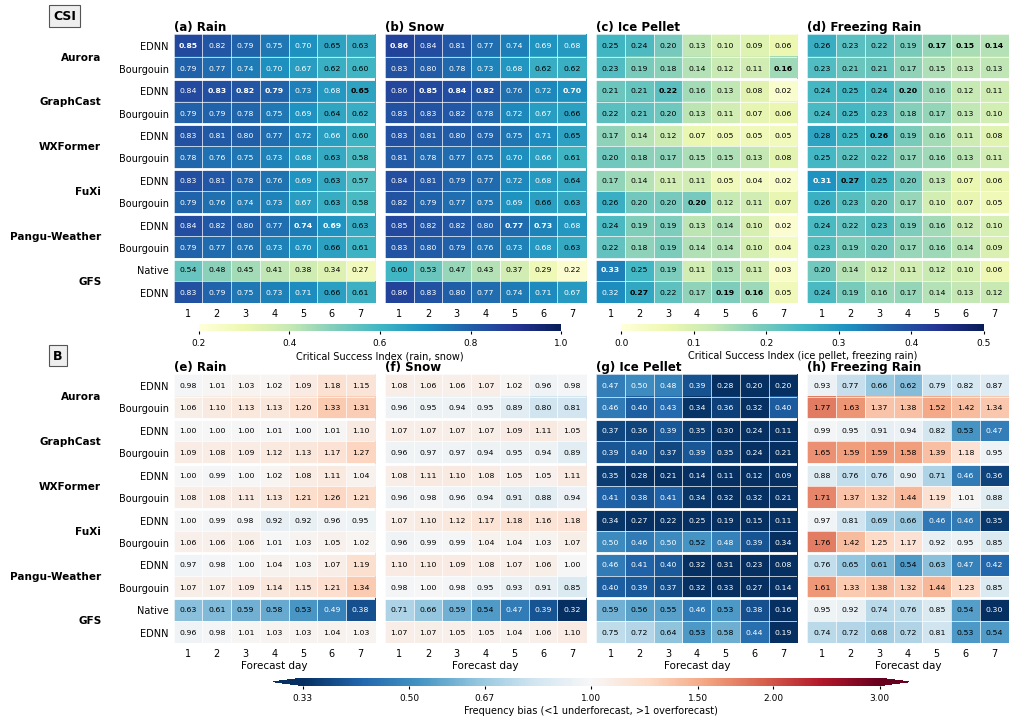

In [12]:
# ============================================================
# 1. Frequency bias per System / Forecast_Day / Class
#    bias = (# forecasts of class) / (# observations of class)
#    Taken directly from `skill`, i.e. computed on the COMMON-VALID
#    sample, identical to the one used for CSI.
# ============================================================
assert {"CSI", "Frequency_Bias"}.issubset(skill.columns)
assert skill.groupby(["Forecast_Day", "Class"]).N.nunique().eq(1).all(), \
    "all systems must be scored on the same sample for a given day"

# ============================================================
# 2. Figure: row 1 = CSI, row 2 = frequency bias
# ============================================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 7.5,
    "axes.titlesize": 8.5,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

n_sys, n_day, n_cls = len(SYSTEM_ORDER), 7, len(CLASS_ORDER)
models  = [s.split(" — ")[0] for s in SYSTEM_ORDER]
methods = [s.split(" — ")[1] for s in SYSTEM_ORDER]
starts = [i for i in range(n_sys) if i == 0 or models[i] != models[i - 1]]
bounds = starts + [n_sys]

CSI_CMAP = plt.get_cmap("YlGnBu")
BIAS_CMAP = plt.get_cmap("RdBu_r")          # red = overforecast, blue = under
# CSI: frequent classes (rain, snow) and rare classes (IP, FZRA) get own scales
CSI_NORMS = [Normalize(0.2, 1.0)] * 2 + [Normalize(0.0, 0.5)] * 2
# Bias: plotted as log2 so 0.5x and 2x are equally far from 1
BIAS_LIM = np.log2(3)
BIAS_NORM = Normalize(-BIAS_LIM, BIAS_LIM)
BIAS_TICKS = [1/3, 1/2, 2/3, 1, 1.5, 2, 3]
BIAS_TICKLABELS = [f"{t:.2f}" for t in BIAS_TICKS]   # 0.33 ... 3.00, log-spaced

# Boxed style for the row labels ("CSI", "Frequency bias")
ROW_LABEL_BOX = dict(boxstyle="square,pad=0.35", facecolor="#eeeeee",
                     edgecolor="#555555", linewidth=0.8)

# Text color (black/white) is for legibility only, chosen from cell brightness.
def text_color(rgba):
    r, g, b = rgba[:3]
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.5 else "white"

def get_grid(cls, metric):
    return (
        skill[skill.Class == cls]
        .pivot(index="System", columns="Forecast_Day", values=metric)
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1, n_day + 1))
    ).values

def style_axis(ax, col):
    ax.set_xticks(np.arange(-.5, n_day, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_sys, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5)
    for b in bounds[1:-1]:
        ax.axhline(b - 0.5, color="white", linewidth=2.0)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(np.arange(n_day), np.arange(1, n_day + 1))
    ax.set_yticks(np.arange(n_sys))
    if col == 0:
        ax.set_yticklabels(methods)
        for a, b in zip(bounds[:-1], bounds[1:]):
            ax.text(-0.36, (a + b - 1) / 2, models[a],
                    transform=ax.get_yaxis_transform(),
                    ha="right", va="center", fontweight="bold")
    else:
        ax.set_yticklabels([])

def annotate(ax, z, colors, best):
    for i in range(n_sys):
        for j in range(n_day):
            v = z[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        fontsize=5.6, color=colors[i, j],
                        fontweight="bold" if best[j] == i else "normal")

fig = plt.figure(figsize=(10.0, 7.4))
# rows: CSI | tick space | CSI cbar | gap | Bias | tick space | Bias cbar
gs = GridSpec(7, n_cls, figure=fig,
              height_ratios=[1, 0.075, 0.028, 0.16, 1, 0.13, 0.028],
              hspace=0, wspace=0.05,
              left=0.155, right=0.99, bottom=0.075, top=0.955)

letters = "abcdefgh"
for c, cls in enumerate(CLASS_ORDER):
    # ---------------- CSI ----------------
    ax = fig.add_subplot(gs[0, c])
    z = get_grid(cls, "CSI")
    norm = CSI_NORMS[c]
    im_csi = ax.imshow(z, cmap=CSI_CMAP, norm=norm, aspect="auto",
                       interpolation="none")
    colors = np.vectorize(lambda v: text_color(CSI_CMAP(norm(v))) if np.isfinite(v) else "k",
                          otypes=[object])(z)
    annotate(ax, z, colors, np.nanargmax(z, axis=0))   # bold = highest CSI per day
    style_axis(ax, c)
    ax.set_title(f"({letters[c]}) {cls}", loc="left", fontweight="bold", pad=3)
    if c == 0:
        ax.text(-0.60, 1.045, "CSI", transform=ax.transAxes,
                fontsize=9, fontweight="bold", ha="left", va="bottom",
                bbox=ROW_LABEL_BOX)
    if c in (1, 3):   # one horizontal colorbar under each class pair
        cax = fig.add_subplot(gs[2, c - 1:c + 1])
        p = cax.get_position()   # inset so the two CSI colorbars don't touch
        cax.set_position([p.x0 + 0.025, p.y0, p.width - 0.05, p.height])
        cb = fig.colorbar(im_csi, cax=cax, orientation="horizontal",
                          ticks=np.arange(norm.vmin, norm.vmax + 1e-9, 0.1 if c == 3 else 0.2))
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=2, labelsize=6.5)
        cb.set_label("Critical Success Index" + (" (rain, snow)" if c == 1 else " (ice pellet, freezing rain)"),
                     fontsize=7, labelpad=2)

    # ---------------- Frequency bias ----------------
    ax = fig.add_subplot(gs[4, c])
    zb = get_grid(cls, "Frequency_Bias")
    lz = np.log2(zb)
    im_b = ax.imshow(lz, cmap=BIAS_CMAP, norm=BIAS_NORM, aspect="auto",
                     interpolation="none")
    colors = np.vectorize(lambda v: text_color(BIAS_CMAP(BIAS_NORM(v))) if np.isfinite(v) else "k",
                          otypes=[object])(lz)
    annotate(ax, zb, colors, np.full(n_day, -1))   # no bolding in bias row
    style_axis(ax, c)
    ax.set_xlabel("Forecast day", labelpad=2)
    ax.set_title(f"({letters[c + 4]}) {cls}", loc="left", fontweight="bold", pad=3)
    if c == 0:
        ax.text(-0.60, 1.045, "B", transform=ax.transAxes,
                fontsize=9, fontweight="bold", ha="left", va="bottom",
                bbox=ROW_LABEL_BOX)

cax = fig.add_subplot(gs[6, :])
p = cax.get_position()
cax.set_position([p.x0 + 0.1, p.y0, p.width - 0.2, p.height])
cb = fig.colorbar(im_b, cax=cax, orientation="horizontal", extend="both",
                  ticks=np.log2(BIAS_TICKS))
cb.ax.set_xticklabels(BIAS_TICKLABELS)
cb.outline.set_visible(False)
cb.ax.tick_params(length=2, labelsize=6.5)
cb.set_label("Frequency bias (<1 underforecast, >1 overforecast)",
             fontsize=7, labelpad=2)

fig.savefig(FIG / "multimodel_csi_bias_heatmap.pdf", dpi=400, bbox_inches="tight")
plt.show()

## Skill loss with lead time across all four classes

In [13]:
df = pd.read_csv(OUT / "multimodel_skill_by_day.csv")
ai = df[~df["System"].str.startswith("GFS")]
w = ai[ai.Forecast_Day.isin([1, 7])].pivot_table(index=["System", "Class"], columns="Forecast_Day", values="CSI")
w["abs"] = w[1] - w[7]
w["rel_%"] = 100 * w["abs"] / w[1]
print(w.round(3))
print(w.groupby("Class")[["abs", "rel_%"]].agg(["min", "max"]).round(2))

Forecast_Day                                 1      7    abs   rel_%
System                    Class                                     
Aurora — Bourgouin        Freezing Rain  0.233  0.132  0.101  43.256
                          Ice Pellet     0.233  0.159  0.074  31.864
                          Rain           0.791  0.603  0.188  23.762
                          Snow           0.830  0.616  0.214  25.838
Aurora — EDNN             Freezing Rain  0.263  0.142  0.121  45.929
                          Ice Pellet     0.250  0.064  0.185  74.210
                          Rain           0.848  0.631  0.217  25.605
                          Snow           0.862  0.676  0.186  21.575
FuXi — Bourgouin          Freezing Rain  0.259  0.052  0.207  79.896
                          Ice Pellet     0.261  0.072  0.189  72.457
                          Rain           0.788  0.585  0.204  25.829
                          Snow           0.823  0.635  0.188  22.884
FuXi — EDNN               Freezing

## EDNN - BOURGOUIN (CSI)

In [14]:


# ---- settings ----
CSV = OUT / "multimodel_skill_by_day.csv"
AGG = "mean"            # "pooled" (from summed counts) or "mean" (avg of daily ΔCSI)
SAVE = False              # write CSV/TeX outputs next to the input CSV

GFS_NAME = "GFS"
MODEL_ORDER = ["Aurora", "GraphCast", "WXFormer", "FuXi", "Pangu-Weather", GFS_NAME]
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
CLASS_LABELS = {"Rain": "Rain", "Snow": "Snow",
                "Ice Pellet": "Ice pellets", "Freezing Rain": "Freezing rain"}
DAYS = list(range(1, 8))
D_FIRST, D_LAST = DAYS[0], DAYS[-1]
SYSTEM_SPLIT = re.compile(r"\s+[\u2014\u2013-]\s+")
SCHEME_ALIASES = {"ednn": "EDNN", "bourgouin": "Bourgouin", "native": "Native"}

# ---- load ----
df = pd.read_csv(CSV)
parts = df["System"].astype(str).str.split(SYSTEM_SPLIT, n=1, expand=True)
df["model"] = parts[0].str.strip()
df["scheme"] = parts[1].str.strip().str.lower().map(SCHEME_ALIASES)
df["day"] = df["Forecast_Day"].astype(int)
df["cls"] = df["Class"].astype(str).str.strip()
df = df[df["day"].isin(DAYS)]
assert not df.duplicated(["model", "scheme", "cls", "day"]).any(), "duplicate rows"

# ---- pair EDNN with its baseline ----
cols = ["N", "TP", "FN", "FP", "CSI"]
rows = []
for model, g in df.groupby("model"):
    base = "Native" if model == GFS_NAME else "Bourgouin"
    e = g[g["scheme"] == "EDNN"].set_index(["cls", "day"])[cols]
    b = g[g["scheme"] == base].set_index(["cls", "day"])[cols]
    m = e.join(b, lsuffix="_e", rsuffix="_b", how="inner").reset_index()
    m["model"], m["baseline"] = model, base
    rows.append(m)
p = pd.concat(rows, ignore_index=True)
p["delta_csi"] = p["CSI_e"] - p["CSI_b"]

mism = p[p["N_e"] != p["N_b"]]
if len(mism):
    print("[warn] N differs between EDNN and baseline:")
    display(mism[["model", "cls", "day", "N_e", "N_b"]])

# ---- summarize: Day 1, Day 7, 7-day aggregate ----
def csi(tp, fn, fp):
    den = tp + fn + fp
    return tp / den if den > 0 else float("nan")

agg_label = "Pooled" if AGG == "pooled" else "Mean"
recs = []
for (model, cls), g in p.groupby(["model", "cls"]):
    g = g.set_index("day")
    if AGG == "pooled":
        s = g[["TP_e", "FN_e", "FP_e", "TP_b", "FN_b", "FP_b"]].sum()
        a = csi(s.TP_e, s.FN_e, s.FP_e) - csi(s.TP_b, s.FN_b, s.FP_b)
    else:
        a = g["delta_csi"].mean()
    recs.append({"model": model, "cls": cls,
                 f"D{D_FIRST}": g["delta_csi"].get(D_FIRST),
                 f"D{D_LAST}": g["delta_csi"].get(D_LAST),
                 agg_label: a})

summ = pd.DataFrame(recs).set_index(["model", "cls"]).unstack("cls").swaplevel(axis=1)
stats = [f"D{D_FIRST}", f"D{D_LAST}", agg_label]
summ = summ.reindex(columns=pd.MultiIndex.from_product([CLASS_ORDER, stats]))
summ = summ.reindex([m for m in MODEL_ORDER if m in summ.index])

display(summ.style.format("{:+.2f}")
            .background_gradient(cmap="RdBu", vmin=-0.15, vmax=0.15, axis=None))

In [15]:
CSV = OUT / "multimodel_skill_by_day.csv"
df = pd.read_csv(CSV)
df[["model", "scheme"]] = df["System"].str.split(r"\s+[—–-]\s+", n=1, expand=True)
d1 = df[(df.Forecast_Day == 1) & (df.model != "GFS")]

for cls in ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]:
    g = d1[d1.Class == cls].pivot(index="model", columns="scheme", values="CSI")
    spread = {s: g[s].max() - g[s].min() for s in ["EDNN", "Bourgouin"]}
    dcsi = g["EDNN"] - g["Bourgouin"]
    print(f"{cls:14s} model spread: EDNN {spread['EDNN']:.3f}, Bourgouin {spread['Bourgouin']:.3f} | "
          f"ΔCSI (EDNN−Bourgouin): {dcsi.min():+.3f} to {dcsi.max():+.3f}")

Rain           model spread: EDNN 0.017, Bourgouin 0.010 | ΔCSI (EDNN−Bourgouin): +0.046 to +0.057
Snow           model spread: EDNN 0.033, Bourgouin 0.023 | ΔCSI (EDNN−Bourgouin): +0.013 to +0.031
Ice Pellet     model spread: EDNN 0.078, Bourgouin 0.059 | ΔCSI (EDNN−Bourgouin): -0.090 to +0.023
Freezing Rain  model spread: EDNN 0.067, Bourgouin 0.032 | ΔCSI (EDNN−Bourgouin): +0.006 to +0.050


## 12. Figure: FAR and POD

- **Top row:** FAR (darker = more false alarms).
- **Bottom row:** POD (darker = more detections).

Values are not bolded, because a system that rarely forecasts a class can have both low FAR and low POD, so neither metric alone identifies the best system. Read these panels together with the frequency-bias panel.

All values come from `skill`, i.e. the common-valid sample.

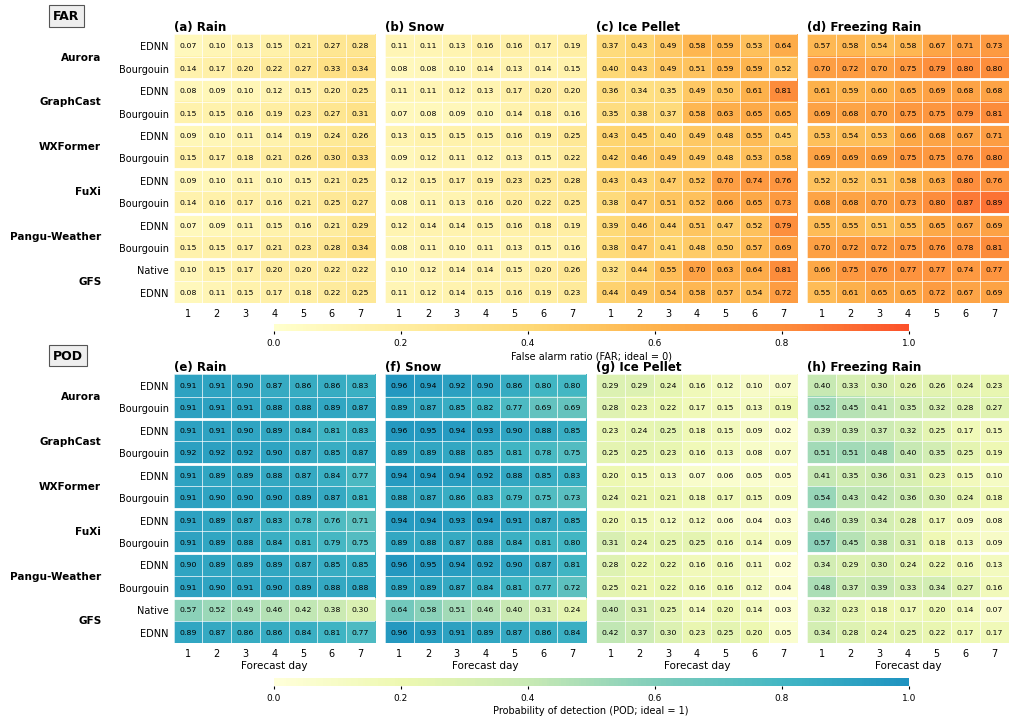

In [16]:
# ============================================================
# 1. FAR and POD per System / Forecast_Day / Class
#    For each class (one-vs-rest):
#      hits (H)         = forecast class & observed class
#      false alarms (F) = forecast class & observed other
#      misses (M)       = forecast other (incl. native GFS -1) & observed class
#    FAR = F / (H + F)   ideal 0   (undefined if class never forecast)
#    POD = H / (H + M)   ideal 1   (undefined if class never observed)
#    Taken directly from `skill`, i.e. the same COMMON-VALID sample
#    used for CSI and frequency bias.
# ============================================================
far_pod = skill[["System", "Forecast_Day", "Class", "FAR", "POD"]].copy()
assert skill.groupby(["Forecast_Day", "Class"]).N.nunique().eq(1).all(), \
    "all systems must be scored on the same sample for a given day"

# ============================================================
# 2. Figure: row 1 = FAR, row 2 = POD
# ============================================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 7.5,
    "axes.titlesize": 8.5,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

n_sys, n_day, n_cls = len(SYSTEM_ORDER), 7, len(CLASS_ORDER)
models  = [s.split(" — ")[0] for s in SYSTEM_ORDER]
methods = [s.split(" — ")[1] for s in SYSTEM_ORDER]
starts = [i for i in range(n_sys) if i == 0 or models[i] != models[i - 1]]
bounds = starts + [n_sys]

def truncate_cmap(name, lo, hi, n=256):
    """Use only the lighter part of a colormap so black text stays readable."""
    return ListedColormap(plt.get_cmap(name)(np.linspace(lo, hi, n)))

# All cell values are printed in black; colormaps are trimmed accordingly.
# FAR: darker = more false alarms (worse). POD: darker = more detections (better).
FAR_CMAP = truncate_cmap("YlOrRd", 0.0, 0.62)
POD_CMAP = truncate_cmap("YlGnBu", 0.0, 0.62)
NORM = Normalize(0.0, 1.0)          # both are rates on [0, 1]; one scale per row
TICKS = np.arange(0.0, 1.01, 0.2)

# No bold "best" values: a system that rarely forecasts a class gets low FAR
# and low POD at the same time, so neither metric alone identifies the best system.

ROW_LABEL_BOX = dict(boxstyle="square,pad=0.35", facecolor="#eeeeee",
                     edgecolor="#555555", linewidth=0.8)

def get_grid(metric, cls):
    return (
        far_pod[far_pod.Class == cls]
        .pivot(index="System", columns="Forecast_Day", values=metric)
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1, n_day + 1))
    ).values

def style_axis(ax, col):
    ax.set_xticks(np.arange(-.5, n_day, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_sys, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5)
    for b in bounds[1:-1]:
        ax.axhline(b - 0.5, color="white", linewidth=2.0)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(np.arange(n_day), np.arange(1, n_day + 1))
    ax.set_yticks(np.arange(n_sys))
    if col == 0:
        ax.set_yticklabels(methods)
        for a, b in zip(bounds[:-1], bounds[1:]):
            ax.text(-0.36, (a + b - 1) / 2, models[a],
                    transform=ax.get_yaxis_transform(),
                    ha="right", va="center", fontweight="bold")
    else:
        ax.set_yticklabels([])

def annotate(ax, z):
    for i in range(n_sys):
        for j in range(n_day):
            v = z[i, j]
            ax.text(j, i, f"{v:.2f}" if np.isfinite(v) else "–",
                    ha="center", va="center", fontsize=5.6, color="black")

fig = plt.figure(figsize=(10.0, 7.4))
# rows: FAR | tick space | FAR cbar | gap | POD | tick space | POD cbar
gs = GridSpec(7, n_cls, figure=fig,
              height_ratios=[1, 0.075, 0.028, 0.16, 1, 0.13, 0.028],
              hspace=0, wspace=0.05,
              left=0.155, right=0.99, bottom=0.075, top=0.955)

ROWS = [
    # (metric, grid row, cbar row, cmap, row label, colorbar label, first letter idx)
    ("FAR", 0, 2, FAR_CMAP, "FAR", "False alarm ratio (FAR; ideal = 0)", 0),
    ("POD", 4, 6, POD_CMAP, "POD", "Probability of detection (POD; ideal = 1)", 4),
]
letters = "abcdefgh"

for metric, grow, crow, cmap, row_label, cbar_label, l0 in ROWS:
    for c, cls in enumerate(CLASS_ORDER):
        ax = fig.add_subplot(gs[grow, c])
        z = get_grid(metric, cls)
        im = ax.imshow(z, cmap=cmap, norm=NORM, aspect="auto",
                       interpolation="none")
        annotate(ax, z)
        style_axis(ax, c)
        ax.set_title(f"({letters[l0 + c]}) {cls}", loc="left",
                     fontweight="bold", pad=3)
        if grow == 4:
            ax.set_xlabel("Forecast day", labelpad=2)
        if c == 0:
            ax.text(-0.60, 1.045, row_label, transform=ax.transAxes,
                    fontsize=9, fontweight="bold", ha="left", va="bottom",
                    bbox=ROW_LABEL_BOX)

    cax = fig.add_subplot(gs[crow, :])
    p = cax.get_position()
    cax.set_position([p.x0 + 0.1, p.y0, p.width - 0.2, p.height])
    cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=TICKS)
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2, labelsize=6.5)
    cb.set_label(cbar_label, fontsize=7, labelpad=2)

fig.savefig(FIG / "multimodel_far_pod_heatmap.pdf", dpi=400, bbox_inches="tight")
plt.show()